# Big Data with DuckDB



<a id="section-1"></a>
## 1 我们要做什么？

学习大数据处理的相关技术，学习使用DuckDB处理百万级别新浪微博数据！

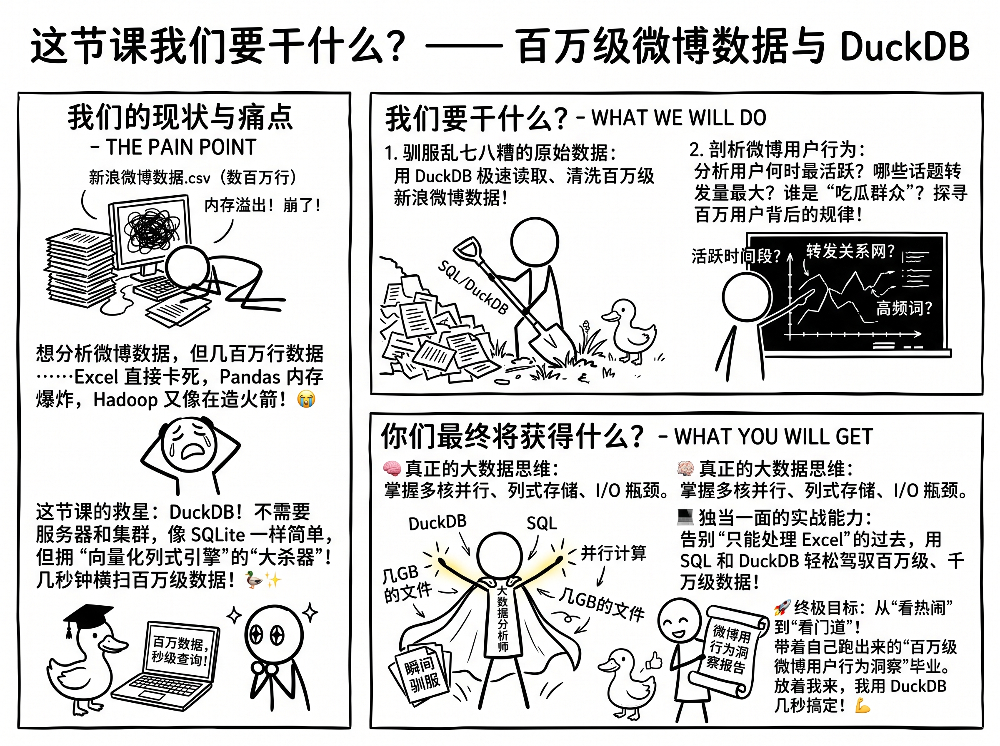

<a id="section-1-1"></a>
### 1.1 数据太大了怎么办？

<a id="section-1-1-1"></a>
#### 1.1.1 大！
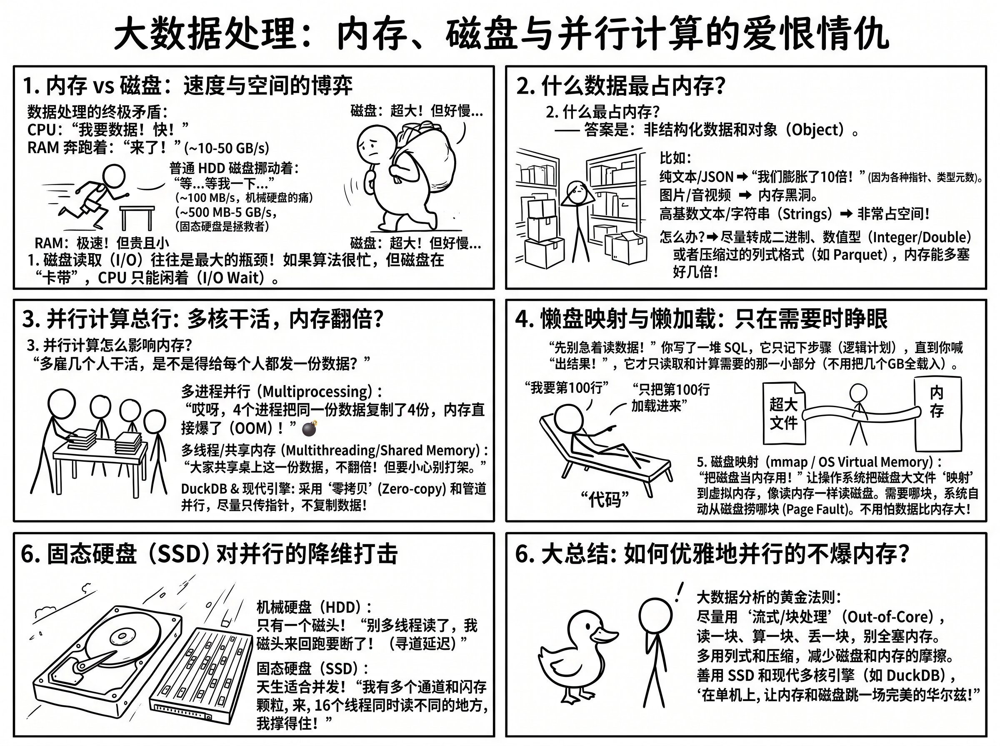

<a id="section-1-1-2"></a>
#### 1.1.2 慢！
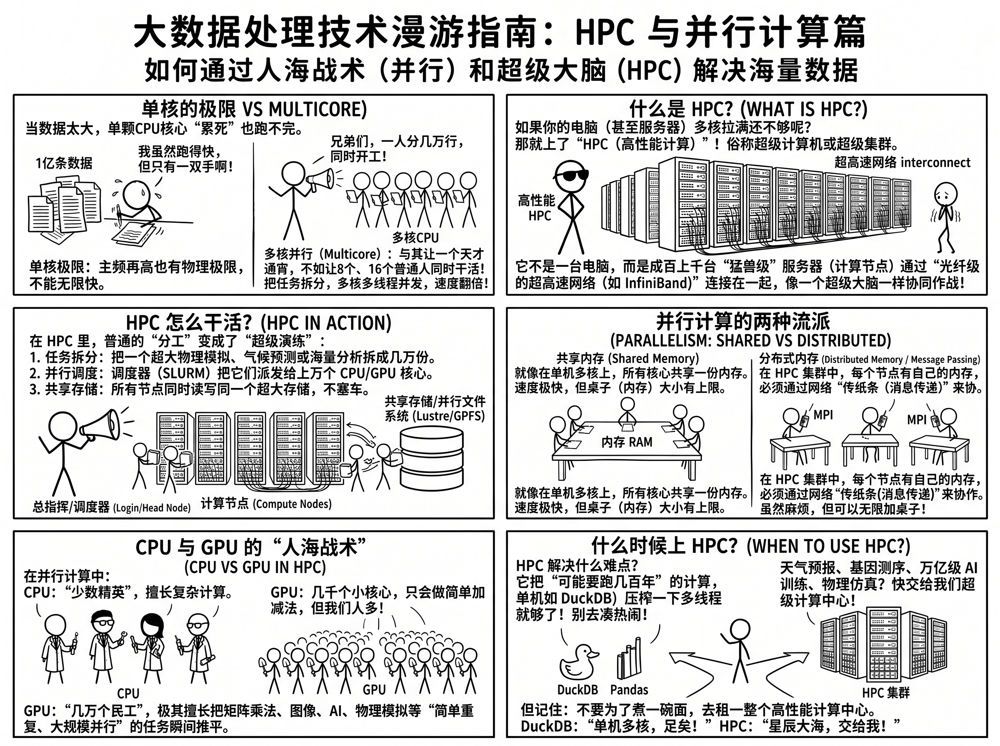


**让我们开始吧**
<!-- course-toc:start -->
<a id="course-toc"></a>
**目录**

- [1 我们要做什么？](#section-1)
  - [1.1 数据太大了怎么办？](#section-1-1)
    - [1.1.1 大！](#section-1-1-1)
    - [1.1.2 慢！](#section-1-1-2)
  - [1.2 我们的数据](#section-1-2)
- [2 环境准备](#section-2)
- [3 103 MiB 的文件，读入后还是 103 MiB 吗？ **\[重点\]**](#section-3)
  - [3.1 可选：测量完整表的内存 **\[拓展\]**](#section-3-1)
- [4 DuckDB 是什么？怎样直接查询文件？ **\[重点\]**](#section-4)
  - [4.1 核对全国规模与质量条件 **\[重点\]**](#section-4-1)
  - [4.2 魔法命令可以组合吗？怎样计时？](#section-4-2)
- [5 SQL 入门：全国哪些城市的记录更多？ **\[重点\]**](#section-5)
  - [5.1 同一个文件，如何只分析四川？ **\[重点\]**](#section-5-1)
- [6 从记录量到用户与内容指标 **\[重点\]**](#section-6)
  - [6.1 全国城市表：记录数、不同用户数与“工作”关键词比例 **\[重点\]**](#section-6-1)
- [7 汇总后绘图：百万条输入，十行画图数据 **\[重点\]**](#section-7)
  - [7.1 用SQL绘制记录数，用Plotly比较关键词比例 **\[重点\]**](#section-7-1)
  - [7.2 用一行命令查看城市指标的分布 **\[拓展\]**](#section-7-2)
- [8 查询计划：引擎实际准备做哪些工作？ **\[拓展\]**](#section-8)
  - [8.1 列裁剪与过滤下推 **\[拓展\]**](#section-8-1)
  - [8.2 看看这一个文件怎样分成行组 **\[拓展\]**](#section-8-2)
- [9 多核与内存：数据继续增大怎么办？ **\[拓展\]**](#section-9)
  - [9.1 多个线程一定比一个线程快吗？ **\[拓展\]**](#section-9-1)
  - [9.2 内存限制和磁盘临时空间 **\[拓展\]**](#section-9-2)
  - [9.3 将两周扩展到全年时，先检查什么？ **\[拓展\]**](#section-9-3)
- [10 操作速查](#section-10)
  - [10.1 查阅 API](#section-10-1)
  - [10.2 结果核对与连接关闭 **\[重点\]**](#section-10-2)
<!-- course-toc:end -->


<a id="section-1-2"></a>
### 1.2 我们的数据

**输入文件：** `tutorials/data/posts_two_weeks.parquet`。
全国窗口为 2022 年 8 月 12–25 日，共 1,254,689 条采集记录、20 列，
Parquet 约 103 MiB；全国可用记录 1,149,693 条。
四川有 54,609 条可用记录，可用于核对 DuckDB 与 Pandas 的计算结果。
“全国”指这个文件内的全国城市标签记录，不表示全平台覆盖或完整用户历史。

<a id="section-2"></a>
## 2 环境准备

在 VS Code 打开整个课程项目，右上角选择课程 Python 内核（Conda 或 venv）。
`tutorials/requirements/environment.yml` 和 `tutorials/requirements/requirements.txt`
都声明了 DuckDB 1.4 LTS。按环境说明选择 Conda 或 uv + venv 安装整套依赖，安装后重启 Notebook 内核。
Conda 的包名为 `python-duckdb`，PyPI 的包名为 `duckdb`；Python 中均使用 `import duckdb`。
本教程使用JupySQL提供的`%%sql`单元格，`duckdb-engine`负责SQLAlchemy连接。基础环境配置已包含这两个依赖。
如果已有课程环境，请按环境说明更新依赖并重启内核。
本教程直接查询本地Parquet，默认分析流程不需要联网，也不需要安装额外的数据库扩展。

[官方 Jupyter 指南](https://duckdb.org/docs/current/guides/python/jupyter)

**运行顺序与路径：** 从上到下运行。这里先确定输入文件，后续在第一次用到时导入库、定义参数和创建输出目录。`Path`按当前系统处理路径；`TUTORIAL_DIR`指向课程的`tutorials`文件夹，无需填写Mac或Windows的绝对路径。

**表格展示：** 单元格最后一行直接写`table`或`table.head()`即可显示；同格需要多张表、或在`if`、循环中展示时，再使用`display(...)`。

In [ ]:
# Path处理相对路径，Mac和Windows无需分别编写路径。
from pathlib import Path
TUTORIAL_DIR = Path('.') if Path('data/posts_two_weeks.parquet').is_file() else Path('tutorials')
# 此处只确定输入文件；绘图、输出目录与计算参数在用到时再设置。
DATA = TUTORIAL_DIR / 'data/posts_two_weeks.parquet'
assert DATA.is_file(), '请保留完整tutorials目录，并从课程目录打开Notebook'

<a id="size"></a>
<a id="section-3"></a>
## 3 103 MiB 的文件，读入后还是 103 MiB 吗？ **[重点]**

先读 Parquet 元数据确认规模，再用前课的四川范围演示 Pandas 的内存估算。
Parquet 按列存储并压缩；Pandas 中的字符串、索引与对象也占内存，所以文件体积与内存占用不能等同。
**行数、字段类型、文本长度和计算方法一起决定资源需求**。百万行并不自动意味着必须用集群。

`MiB = 字节 / 1024²`；`memory_usage(deep=True)` 尝试计入字符串等对象，
是表内存估算，不是整个 Python 进程的峰值，也不计入后续计算的全部临时对象。

In [ ]:
# 读取和处理表格时导入Pandas。
import pandas as pd
# 查看Parquet字段和元数据时导入PyArrow。
import pyarrow.parquet as pq
# 同一格展示多张表或在分支中显示结果时使用display。
from IPython.display import display

# 打开 Parquet 元数据接口；查看模式和行组不需要先把全部记录变成 Pandas 表。
parquet = pq.ParquetFile(DATA)
# 从文件状态与 Parquet 元数据读取磁盘体积、行列数和行组数，并格式化为展示表。
file_info = pd.Series({
    '文件字节数': f'{DATA.stat().st_size:,}',  # stat().st_size 是文件在磁盘上的字节数，:, 加千分位。
    '文件大小（MiB）': f'{DATA.stat().st_size / 1024**2:.2f}',  # 1 MiB = 1024² 字节；:.2f 保留两位小数。
    '记录数': f'{parquet.metadata.num_rows:,}',  # 从文件元数据读取总行数，不把正文读入内存。
    '列数': str(parquet.metadata.num_columns),  # 读取模式中的字段数量。
    '行组数': str(parquet.metadata.num_row_groups),  # 行组是 Parquet 存储块，查询可以利用块内列统计跳过无关块。
}, name='实际规模')
# 将 Series 转成单列表格并显示，便于一起查看行标签与统计值。
display(file_info.to_frame())
# 只将四川可用记录的三列读入Pandas，用于内存估算与省级计数核对，不另造数据源。
sc_small = pd.read_parquet(DATA, columns=['city', 'user_id', 'text'],
    filters=[('province_code', '==', '51'), ('usable_text', '==', True)])  # 过滤条件为四川省编码 51 且文本可用；同一组条件按“并且”组合。
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('四川可用记录、用户数：', len(sc_small), sc_small['user_id'].nunique())
# deep=True 估算字符串等对象的内存；sum 汇总各列，除以 1024 或 1024² 转为 KiB / MiB。
print('仅这三列的 Pandas 表内存估算（MiB）：',
      round(sc_small.memory_usage(deep=True).sum() / 1024**2, 2))

<a id="section-3-1"></a>
### 3.1 可选：测量完整表的内存 **[拓展]**

下面这格的`RUN_FULL_MEMORY_DEMO = True`会执行完整20列的内存测量；内存较小的电脑可在本格改为`False`。后续DuckDB查询不依赖整表读入。
完整读取 20 列的内存占用需在当前环境中测量；类型和软件版本会影响结果。
这里读取全部字段，以比较文件体积与表内存；实际查询应先确定需要哪些列。
删除变量可释放对象引用，进程内存不保证立刻全部还给系统。

In [ ]:
# 删除整表后可请求回收不再使用的内存对象。
import gc

# 本格才用到整表读入；内存较小的电脑可改为False。
RUN_FULL_MEMORY_DEMO = True
# 用 None 表示整表内存尚未测量，避免把未运行误写成 0 MiB。
full_memory_mib = None
# 只有准备单元的开关为True才读入整表；关闭时直接继续DuckDB查询。
if RUN_FULL_MEMORY_DEMO:
    # 整表读入 Pandas 会物化所有列和记录，内存通常比压缩后的磁盘文件大。
    full_demo = pd.read_parquet(DATA)
    # deep=True 计入字符串对象；汇总所有列和索引的估算字节数，再转为 MiB。
    full_memory_mib = full_demo.memory_usage(deep=True).sum() / 1024**2
    # 打印计算结果，核对数量、分母、阈值或运行状态。
    print('完整表行列数：', full_demo.shape)
    # 打印计算结果，核对数量、分母、阈值或运行状态。
    print('完整表内存估算（MiB）：', round(full_memory_mib, 2))
    # 打印计算结果，核对数量、分母、阈值或运行状态。
    print('估算与 Parquet 文件体积的比值：',
          round(full_memory_mib / (DATA.stat().st_size / 1024**2), 2))
    # 删除大表变量的引用，让不再使用的内存对象有机会被回收。
    del full_demo
    # 请求垃圾回收；释放对象不保证进程占用内存立即完全归还操作系统。
    gc.collect()
else:
    # 显示指标的口径说明，解释这一步结果应如何理解。
    print('整表内存演示未启用；继续用 DuckDB 查询全国记录。')

<a id="connect"></a>
<a id="section-4"></a>
## 4 DuckDB 是什么？怎样直接查询文件？ **[重点]**


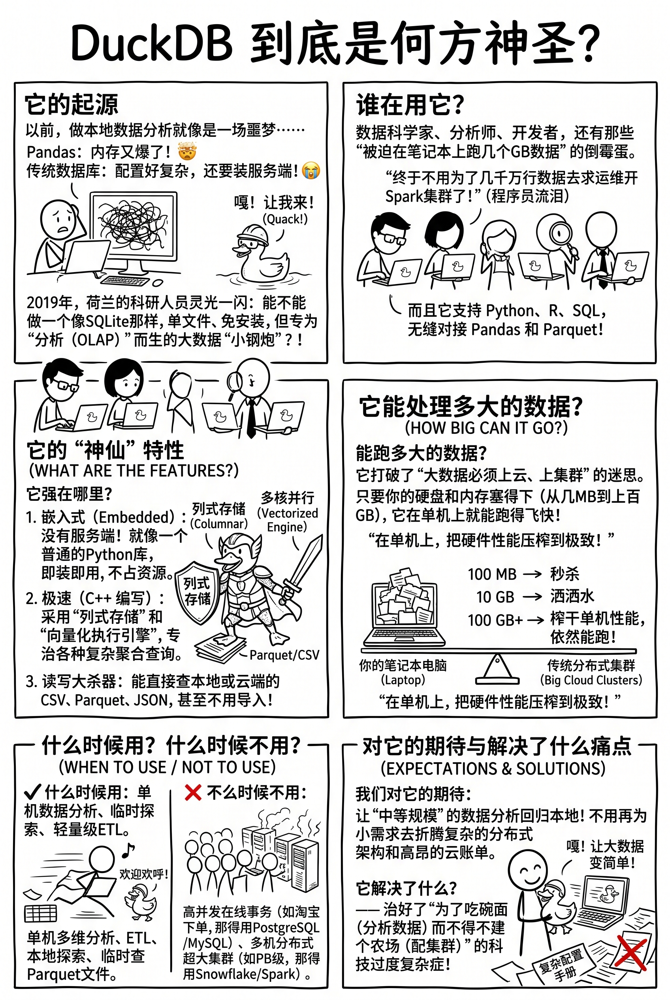



用 DuckDB 直接查询 Parquet 文件，学习 SQL 筛选与聚合、查询计划、多核计算与内存管理。
重点是在读取和计算过程中减少不需要的列、行和中间结果，再用`%sqlplot`或Plotly展示汇总结果。
DuckDB 是运行在当前 Python 进程内的分析型数据库引擎。
创建连接后，可以直接查询 Parquet，不需要先运行数据库服务器。
这里的 `:memory:` 表示数据库目录在内存中；源数据仍来自磁盘上的 Parquet，
并不表示要把整份文件全部复制进内存。

`posts` 是一个**视图**：保存“从哪里读数据”的查询定义。建立视图不会另复制一份帖子表。
真正执行查询时仍会消耗读取、解压和计算资源。
`%%sql`将整格交给SQL引擎执行；普通SQL格将它写在第一行，SQL注释使用`--`。第4.2节介绍用外层`%%time`为SQL格计时。
`%sql`用于连接、关闭连接等单行命令。`%%sql overview <<`把最后一条查询结果存入Python变量`overview`；开启`autopandas`后，它是Pandas DataFrame。
SQL正文中只写SQL；Python的`display`、`%sqlplot`和Plotly绘图放在后续Python格中。

`{{PARQUET_PATH}}`把紧邻连接格准备的文件路径填入SQL。省编码、关键词和源日期分别在省级分析、内容分析和单日查询中设置；用`SET VARIABLE`设置，用`getvariable`读取。修改参数后重跑相关查询，不会改写Parquet源文件。

[Python API](https://duckdb.org/docs/lts/clients/python/overview)
与 [Parquet 视图](https://duckdb.org/docs/lts/data/parquet/overview)

In [ ]:
# 文件路径转成SQL文字：正斜杠兼容Windows，两个单引号表示路径中的一个单引号。
PARQUET_PATH = DATA.as_posix().replace("'", "''")
# 加载JupySQL扩展，之后即可使用%sql和%%sql。
%load_ext sql
# 查询结果直接转成Pandas小表；关闭重复的连接提示与行数反馈。
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
# 同一连接内连续运行SQL，保留查询计划的返回结果；本课不修改外部数据库。
%config SqlMagic.autocommit = False
# 创建本机内存数据库连接；duckdb-engine提供SQLAlchemy驱动，不需要数据库服务器。
%sql duckdb:///:memory: --alias course_duckdb

In [ ]:
%%sql
-- 本机连接先使用4个线程；多核章节再观察线程数的影响。
SET threads = 4;
-- 视图保存读取定义，建立视图不把全部帖子复制为Pandas大表。
CREATE OR REPLACE VIEW posts AS
SELECT * FROM read_parquet('{{PARQUET_PATH}}');
-- 先观察三行日期和城市，下一格再检查完整字段结构。
SELECT date, city FROM posts LIMIT 3;

In [ ]:
%%sql
-- 查看视图字段和类型；没有读取并展示全部帖子。
DESCRIBE posts;

<a id="section-4-1"></a>
### 4.1 核对全国规模与质量条件 **[重点]**

`COUNT(*)` 数行；`COUNT(DISTINCT user_id)` 数不同的非空用户 ID。
`FILTER (WHERE ...)` 只限定它前面的聚合，便于把原始和可用计数放在同一行。
`usable_text` 是已有质量标记，沿用前课规则，不能把不可用记录混进内容比例的分母。

In [ ]:
%%sql overview <<
SELECT COUNT(*) AS n_raw,  -- COUNT(*) 统计记录行数；AS 给结果列命名。
       COUNT(*) FILTER (WHERE usable_text) AS n_usable,  -- FILTER 仅筛选这个计数的输入，不会自动过滤其他指标。
       COUNT(DISTINCT user_id) FILTER (WHERE usable_text) AS n_usable_users,  -- COUNT(DISTINCT) 去重数用户；同一组内重复用户只计一次。
       MIN(date) AS start_date, MAX(date) AS end_date,  -- 取得窗口中最早、最晚日期。
       COUNT(DISTINCT date) AS n_dates  -- 去重数日期，得到实际出现记录的不同日期数。
FROM posts;  -- 指定数据视图、中间查询或配置表作为输入。

In [ ]:
# SQL已将百万行汇总为一行；与Parquet元数据核对总记录数。
display(overview)
assert int(overview.loc[0, 'n_raw']) == parquet.metadata.num_rows

**结果解读：** 输出仍只有一行。1,254,689 是原始行数，1,149,693 是可用记录数；
用户数需要在选定质量范围内去重。这里的用户是已观测匿名用户，不是人口规模。
`date` 源字段采用统一的 `YYYY-MM-DD` 字符串，本例可用于核对两周窗口。

<a id="section-4-2"></a>
### 4.2 魔法命令可以组合吗？怎样计时？

`%`是行魔法命令，同一个Python代码格可以有多条，例如连接格中的`%load_ext`、`%config`和`%sql`。
`%%`是单元魔法命令，会接管后续整个单元的内容；能否嵌套取决于外层命令怎样处理这些内容。

本课程的IPython内核支持下面的组合：第一行写`%%time`，第二行写`%%sql`，然后写SQL。下一节的查询将实际演示这一写法。

```text
%%time
%%sql national_counts <<
SELECT city, COUNT(*) AS n_posts
FROM posts
WHERE usable_text
GROUP BY city
ORDER BY n_posts DESC, city;
```

`%%time`会继续解析内层魔法命令；顺序不能颠倒，`%%sql`会把后面的`%%time`当成SQL文本。
一条SQL也可写成`%time %sql SELECT COUNT(*) FROM posts;`。

输出中，`Wall time`是这一格的实际经过时间，包含JupySQL处理、SQL执行和结果转换；部分结果转换路径可能再次执行查询。
`CPU times`统计当前进程各线程使用的CPU时间，多线程时可能大于`Wall time`。
两者都不是整个Notebook的总耗时，也不能直接等同于磁盘读取时间。
需要检查引擎执行算子与耗时，用第8节的`EXPLAIN ANALYZE`；缓存与运行顺序会影响两种计时结果，单次运行不能作为严格性能基准。

[IPython计时命令](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-time)

<a id="sql"></a>
<a id="section-5"></a>
## 5 SQL 入门：全国哪些城市的记录更多？ **[重点]**

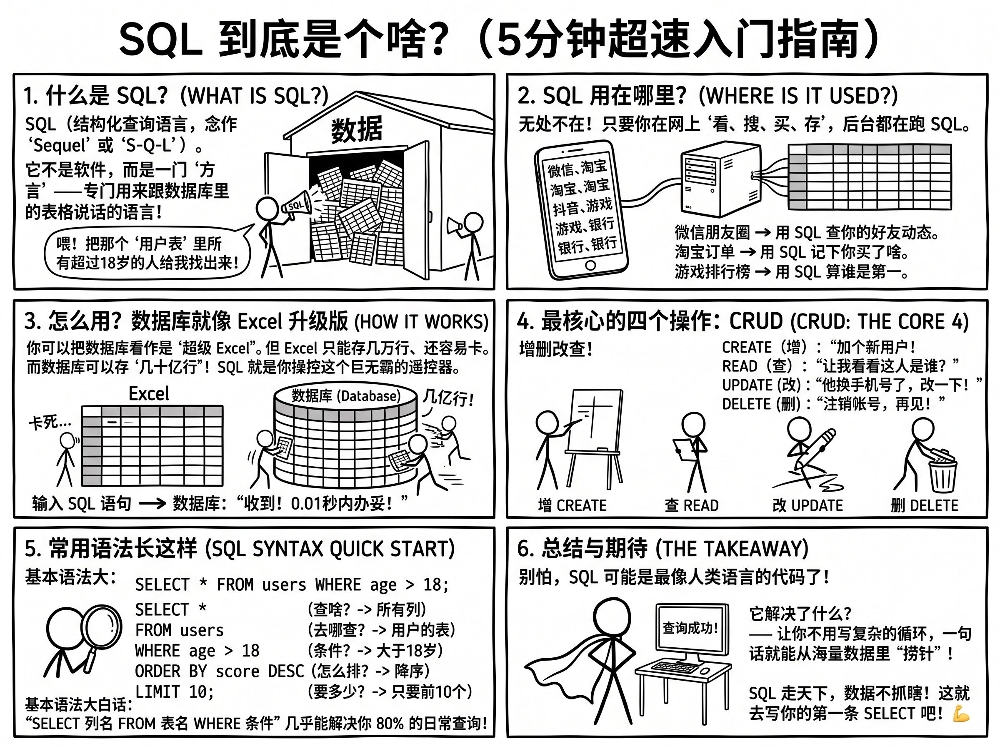

从前面的 Pandas 操作理解 SQL：

| SQL | 做什么 | Pandas 中熟悉的操作 |
|---|---|---|
| `FROM posts` | 确定输入 | 选择 DataFrame |
| `WHERE usable_text` | 筛选可用记录 | 布尔条件筛选 |
| `GROUP BY city` | 每个城市一组 | `groupby('city')` |
| `COUNT(*) AS n_posts` | 每组数行并命名 | `size()` |
| `ORDER BY n_posts DESC, city` | 按数量降序，城市名处理并列 | `sort_values` |
| `LIMIT 5` | 限制输出行数 | `head(5)` |

阅读时可按“从哪里读 → 保留哪些行 → 怎样分组 → 算什么 → 排序”理解。
我们先保留完整城市汇总表，再用 `head(10)` 显示前十项，方便后面核对总量。

In [ ]:
%%time
%%sql national_counts <<
SELECT city, COUNT(*) AS n_posts  -- COUNT(*) 统计记录行数；AS 给结果列命名。
FROM posts  -- 指定数据视图、中间查询或配置表作为输入。
WHERE usable_text  -- 过滤记录；WHERE 先于分组与汇总生效。
GROUP BY city  -- 按城市归组，每个城市返回一行汇总。
ORDER BY n_posts DESC, city;  -- 按指定字段排序；DESC 为降序，第二个排序字段用于打破并列。

In [ ]:
# autopandas=True使SQL汇总结果成为Pandas DataFrame。
type(national_counts)

In [ ]:
# 查看完整城市汇总的前十项，并检查总量与小表内存。
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('全国城市汇总行数：', len(national_counts))
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('汇总记录数：', national_counts['n_posts'].sum())
# deep=True 估算字符串等对象的内存；sum 汇总各列，除以 1024 或 1024² 转为 KiB / MiB。
print('汇总表内存估算（KiB）：', round(national_counts.memory_usage(deep=True).sum() / 1024, 2))
# 最后一行直接展示表格。
national_counts.head(10)

**结果解读：** 百万条输入被聚合成每城市一行。城市标签按源字段解释，
数量差异也可能来自采集覆盖；不能据此给城市居民的活跃程度排名。
源数据的 `Unknown` 表示城市未知，不是一座城市：汇总表保留它以核对全部记录，
后面的城市排名图会排除它，并单独报告其记录数。
`LIMIT` 限制的是最终输出；含排序、分组时，返回五行也可能需要先处理大量输入。

<a id="section-5-1"></a>
### 5.1 同一个文件，如何只分析四川？ **[重点]**

省编码是字符串，四川为`'51'`。本格开头设置`province_code`，查询用`getvariable('province_code')`读取它。
修改本格的`SET VARIABLE province_code = '51'`并重新运行本格，即可查看其他省编码；内存演示中的`sc_small`仍固定使用四川；更换省编码后，要区分两个结果的输入范围。

In [ ]:
%%sql province_overview <<
-- 到省级分析时再设置省编码；51表示四川。
SET VARIABLE province_code = '51';
SELECT getvariable('province_code') AS province_code, COUNT(*) AS n_posts, COUNT(DISTINCT user_id) AS n_users  -- COUNT(*) 数帖子行；COUNT(DISTINCT user_id) 在组内去重数用户。
FROM posts  -- 指定数据视图、中间查询或配置表作为输入。
WHERE usable_text AND province_code = getvariable('province_code');  -- 过滤记录；WHERE 先于分组与汇总生效。

In [ ]:
# 显示省级汇总；这里使用第4节中设置的省编码。
province_overview

<a id="metrics"></a>
<a id="section-6"></a>
## 6 从记录量到用户与内容指标 **[重点]**

<a id="section-6-1"></a>
### 6.1 全国城市表：记录数、不同用户数与“工作”关键词比例 **[重点]**

这张表的一行是一个城市标签：

- `n_posts`：可用帖子记录数。
- `n_users`：该城市标签内的不同匿名用户数。
- `n_work`：正文含指定关键词的记录数；`contains` 做字面匹配。
- `work_share`：命中记录数 / 该城市全部可用记录数。
- `posts_per_user`：记录数 / 该城市不同用户数。

`WITH counts AS (...)` 将中间汇总命名，便于下一步计算比例；它本身不要求保存一张磁盘表。
`COALESCE(text, '')` 把缺失正文视为空字符串；`NULLIF(分母, 0)` 避免除零。
同一用户可能出现于多个城市标签，所以各城市用户数相加不一定等于全国去重用户数。

In [ ]:
%%sql parameters <<
-- 在内容分析开始时指定关键词；修改后重跑本节及后续相关查询。
SET VARIABLE keyword = '工作';
-- 保存城市指标的查询定义，后面复用同一视图。
CREATE OR REPLACE VIEW city_metrics AS
WITH counts AS (  -- 定义仅在本次查询中使用的中间计数结果。
    SELECT city,  -- 指定这一层查询要返回的字段或表达式。
           COUNT(*) AS n_posts,  -- COUNT(*) 统计记录行数；AS 给结果列命名。
           COUNT(DISTINCT user_id) AS n_users,  -- COUNT(DISTINCT) 去重数用户；同一组内重复用户只计一次。
           COUNT(*) FILTER (WHERE contains(COALESCE(text, ''), getvariable('keyword'))) AS n_work  -- COALESCE 将缺失正文换为空串；contains 按字面关键词检测，getvariable读取当前连接中设置的关键词。
    FROM posts  -- 指定数据视图、中间查询或配置表作为输入。
    WHERE usable_text  -- 过滤记录；WHERE 先于分组与汇总生效。
    GROUP BY city  -- 按城市归组，每个城市返回一行汇总。
)
SELECT city, n_posts, n_users, n_work,  -- 指定这一层查询要返回的字段或表达式。
       n_work * 1.0 / NULLIF(n_posts, 0) AS work_share,  -- NULLIF 把零分母变成 NULL；乘 1.0 明确使用小数比例。
       n_posts * 1.0 / NULLIF(n_users, 0) AS posts_per_user  -- NULLIF 把零分母变成 NULL；乘 1.0 明确使用小数比例。
FROM counts  -- 指定数据视图、中间查询或配置表作为输入。
ORDER BY n_posts DESC, city;  -- 按指定字段排序；DESC 为降序，第二个排序字段用于打破并列。
-- 最后一条SELECT显示当前关键词，保持图题与SQL计算一致。
SELECT getvariable('keyword') AS keyword;

In [ ]:
# 从紧邻的SQL参数结果读取关键词，供后面的图题使用。
KEYWORD = parameters.loc[0, 'keyword']
parameters

In [ ]:
%%time
%%sql national_city <<
-- 执行视图查询，只将每城市一行的汇总结果交给Python。
SELECT * FROM city_metrics ORDER BY n_posts DESC, city;

In [ ]:
# 两种用户数的分母范围不同；查看结果并核对口径。
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('关键词：', KEYWORD)
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('可用记录中的全国不同用户数：', int(overview.loc[0, 'n_usable_users']))
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('各城市用户数之和：', int(national_city['n_users'].sum()))
# 最后一行直接展示表格。
national_city.head(10)

**结果解读：** 关键词比例描述文字命中，不表示职业、工作状态、偏好或心理状态。
`posts_per_user` 是采集记录的平均数，不能替代中位数，也不能当成完整历史的发帖频率。
在本节SQL开头更换`SET VARIABLE keyword`后重跑本节及后续相关单元，`work_share`的计算含义随之改变；图题和Pandas对照从同一份参数表读取关键词。

<a id="plot"></a>
<a id="section-7"></a>
## 7 汇总后绘图：百万条输入，十行画图数据 **[重点]**

简单的柱形图、直方图可以用JupySQL的`%sqlplot`；数据库负责查询和所需统计，命令负责画图。
它底层使用Matplotlib，环境中仍需保留该依赖，但这里无需直接编写Matplotlib绘图代码。
需要交互、百分比刻度或定制悬浮信息时，将已汇总的小表交给Plotly。

<a id="section-7-1"></a>
### 7.1 用SQL绘制记录数，用Plotly比较关键词比例 **[重点]**

先排除城市未知标签，再取记录最多的十个城市；两张图用同一组城市、同一顺序。
这是按记录量选择的十个城市，**不是关键词比例最高的十个城市**。

`city_top10`是DuckDB视图，供`%sqlplot`查询；`top10`是Python中的十行DataFrame，供Plotly读取。
`%sqlplot bar --column city n_posts`的两个列名分别表示类别和柱高；只传`city`会重新数每个类别的行数，含义不同。
SQL图的轴标签沿用字段名：`city`为城市，`n_posts`为可用记录数。

第二张图的悬浮信息同时显示关键词命中数、可用记录数与不同用户数，便于核对比例分母。
Plotly的浏览器交互处理这十行小表，不会在拖动或悬停时重新扫描原始Parquet。

如果直接执行`SELECT * FROM posts`并转换成Pandas，仍会把大量原始数据载入内存；关键是先确定最终需要的结果规模。

[%sqlplot命令参考](https://jupysql.readthedocs.io/en/latest/api/magic-plot.html)

In [ ]:
%%sql unknown_city <<
-- 保留未知标签，便于总量核对；不进入城市排名图。
SELECT * FROM city_metrics WHERE city IS NULL OR city = 'Unknown';

In [ ]:
%%sql known_city <<
-- 视图供后续SQL绘图复用；未知城市仍在原始汇总表中保留。
CREATE OR REPLACE VIEW known_city_metrics AS
SELECT * FROM city_metrics WHERE city IS NOT NULL AND city <> 'Unknown';
-- 将已知城市汇总结果交给Python，用于末尾核对总量。
SELECT * FROM known_city_metrics ORDER BY n_posts DESC, city;

In [ ]:
%%sql top10 <<
-- 数据库视图供%sqlplot读取，Python变量top10供Plotly读取。
CREATE OR REPLACE VIEW city_top10 AS
-- 先按记录量取前十项，再按绘图顺序升序排列；两张图用同一批城市。
WITH selected AS (
    SELECT * FROM city_metrics
    WHERE city IS NOT NULL AND city <> 'Unknown'
    ORDER BY n_posts DESC, city
    LIMIT 10
)
SELECT * FROM selected ORDER BY n_posts, city;
-- 仍只把十行汇总交给Python，不读取全部原始帖子。
SELECT * FROM city_top10 ORDER BY n_posts, city;

In [ ]:
# city是类别，n_posts是已经计算的柱高；h表示横向。
%sqlplot bar --table city_top10 --column city n_posts --orient h

In [ ]:
# 现在绘制交互图：Plotly Express用表格列名指定图形。
import plotly.express as px
import plotly.io as pio
# 同时兼容VS Code显示和离线HTML导出。
pio.renderers.default = 'plotly_mimetype+notebook'
px.defaults.template = 'simple_white'

# Plotly只接收十行汇总；悬停时同时查看分子、分母和用户数。
fig_share = px.bar(top10, x='work_share', y='city', orientation='h',
    title=f'同一组城市：“{KEYWORD}”关键词比例',
    labels={'work_share': '占本城市可用记录的比例', 'city': '源数据城市标签',
            'n_work': '命中记录数', 'n_posts': '可用记录数', 'n_users': '不同用户数'},
    hover_data={'work_share': ':.2%', 'n_work': True, 'n_posts': True, 'n_users': True})
# 显示百分比但保留0–1原值；固定顺序，与上一张柱形图对应。
fig_share.update_xaxes(tickformat='.1%')
fig_share.update_yaxes(categoryorder='array', categoryarray=top10['city'].tolist())
# show把交互图嵌入当前Notebook输出。
fig_share.show()
# 未知城市只从排名图排除；它的记录仍参与全国总量核对。
print('送入画图的城市数：', len(top10), '；未知城市可用记录：', int(unknown_city['n_posts'].sum()))

<a id="section-7-2"></a>
### 7.2 用一行命令查看城市指标的分布 **[拓展]**

柱形图比较具体城市；直方图观察一项数值指标的整体分布。
下面用`%sqlplot histogram`将已知城市的`posts_per_user`划成15个等宽区间，纵轴统计每个区间的城市数。
分箱计算由数据库完成，绘图端接收分箱结果，不需要把百万条原始帖子读入Pandas。

这里**每个城市贡献一个数值**，不是全国用户的记录数分布，也不是按帖子数加权的分布。
`posts_per_user`是某城市可用采集记录数除以该城市不同用户数；少量样本的城市也占一个观测，解读时需要结合记录量。
调整`--bins`会改变分箱细节，不会改变输入记录或指标定义。

In [ ]:
%%sql
-- 查看已知城市汇总表，明确下一张直方图每行代表一个城市。
SELECT * FROM known_city_metrics ORDER BY n_posts DESC, city;

In [ ]:
# table指定数据库视图，column指定数值列，bins指定等宽分箱数。
%sqlplot histogram --table known_city_metrics --column posts_per_user --bins 15

<a id="plan"></a>
<a id="section-8"></a>
## 8 查询计划：引擎实际准备做哪些工作？ **[拓展]**

前面把百万条帖子汇总成城市表，随后只用十行结果绘图。结果表告诉我们“算出了什么”，但看不出数据库为了它读取和处理了多少数据。
如果把两周扩展到全年，查询变慢时，应该先检查读取和计算的步骤，再决定是否增加线程、内存或更换工具。

**查询计划就是数据库执行SQL的步骤说明。** 我们写下要哪些结果，DuckDB会选择怎样扫描文件、应用筛选、分组计数和排序；其中每一步称为一个算子。
计划用来回答三个具体问题：是否只读取需要的列？日期和质量筛选有没有交给读取阶段？大量工作发生在文件扫描、聚合还是排序？

<a id="section-8-1"></a>
### 8.1 列裁剪与过滤下推 **[拓展]**

沿用城市计数，只将范围缩小到一个`source_date`。它是采集源文件日期，此处用于讲文件扫描；不能直接当作发帖时间。
本次查询的处理流程可先理解为：**读Parquet所需列 → 筛选日期与可用记录 → 按城市计数 → 按记录数排序**。
下面先看数据库准备怎样做，再实际执行并核对结果。

| 命令 | 会实际执行这条查询吗？ | 重点看什么？ |
|---|---|---|
| `EXPLAIN` | 不执行数据查询，但生成计划可能读取模式和统计信息 | 读取列、筛选条件、算子与估计行数 |
| `EXPLAIN ANALYZE` | 会执行，并返回计划及统计 | 实际输出行数与执行时间 |
| `%%time` | 会运行整个单元格 | 包括JupySQL处理、SQL执行和结果转换的整格耗时 |

**先看计划时，找最下方的扫描节点，再沿连线往上读。** 这条简单查询常见以下算子；名称和细节会随版本与查询变化。

| 计划中的文字 | 在这条查询中表示什么？ |
|---|---|
| `READ_PARQUET` / `TABLE_SCAN` | 从文件读取；`Projections`看需要输出的列，`Filters`看读取阶段应用的条件 |
| `PROJECTION` | 选择或计算后续步骤需要的列，不表示把整表转成Pandas |
| `HASH_GROUP_BY` | 按城市分组，并对每组累计记录数 |
| `ORDER_BY` | 对聚合后的城市结果排序 |

统计城市数量不需要正文、网格坐标和情绪分数；这些字段可以不读，这叫**列裁剪**。将日期和`usable_text`条件交给扫描阶段处理，叫**过滤下推**；过滤所用列仍可能需要读取。
`~... rows`是估计行数，不是已经读取或实际返回的行数，更不能单凭它宣称跳过了多少文件块。

统计查询通常返回Pandas表；计划是长文本。下方暂时关闭`autopandas`，保留JupySQL结果对象，用`[0][1]`完整打印第一行第二列的计划文字，读完后恢复。

[EXPLAIN说明](https://duckdb.org/docs/lts/guides/meta/explain)与[EXPLAIN ANALYZE说明](https://duckdb.org/docs/lts/guides/meta/explain_analyze)。

In [ ]:
# 查询计划是长文本，暂时保留JupySQL结果对象，避免自动转换时丢失计划。
%config SqlMagic.autopandas = False

In [ ]:
%%sql plan_result <<
-- 只统计这一源文件日期；在提出单日查询时再设置它。
SET VARIABLE source_day = '2022-08-12';
-- EXPLAIN只生成计划，不执行扫描。
EXPLAIN
SELECT city, COUNT(*) AS n_posts  -- COUNT(*) 统计记录行数；AS 给结果列命名。
FROM posts  -- 指定数据视图、中间查询或配置表作为输入。
WHERE usable_text AND source_date = getvariable('source_day')  -- 过滤记录；WHERE 先于分组与汇总生效。
GROUP BY city  -- 按城市归组，每个城市返回一行汇总。
ORDER BY n_posts DESC, city;  -- 按指定字段排序；DESC 为降序，第二个排序字段用于打破并列。

In [ ]:
# 完整打印计划文字，避免DataFrame把长字符串截短。
# [0][1]取结果第一行的第二列，即完整的计划文字。
plan_text = plan_result[0][1]
print(plan_text)

**读完上面的计划，再回答：** 扫描节点是否只输出`city`？`Filters`中能否看到源日期和`usable_text`？上方的聚合与排序分别对应SQL的哪两句？

现在使用同一条查询的`EXPLAIN ANALYZE`。比较估计行数与实际行数，观察`Total Time`；各算子时间可能存在累计或并行关系，不要简单相加当作总耗时。之后再直接运行普通`SELECT`，得到城市表并核对当天记录总数。

计划帮助我们检查工作量和可能的瓶颈，并不保证某种写法一定更快。比较性能仍需保持数据、筛选条件和指标一致，并考虑缓存与运行顺序。

In [ ]:
%%sql analyzed_result <<
-- EXPLAIN ANALYZE会实际执行查询并返回运行统计。
EXPLAIN ANALYZE
SELECT city, COUNT(*) AS n_posts  -- COUNT(*) 统计记录行数；AS 给结果列命名。
FROM posts  -- 指定数据视图、中间查询或配置表作为输入。
WHERE usable_text AND source_date = getvariable('source_day')  -- 过滤记录；WHERE 先于分组与汇总生效。
GROUP BY city  -- 按城市归组，每个城市返回一行汇总。
ORDER BY n_posts DESC, city;  -- 按指定字段排序；DESC 为降序，第二个排序字段用于打破并列。

In [ ]:
# 阅读真实执行统计；行数与时间以本次运行结果为准。
analyzed_plan = analyzed_result[0][1]
print(analyzed_plan)
# 后续统计查询继续返回Pandas小表。
%config SqlMagic.autopandas = True

In [ ]:
%%sql day_city <<
SELECT city, COUNT(*) AS n_posts  -- COUNT(*) 统计记录行数；AS 给结果列命名。
FROM posts  -- 指定数据视图、中间查询或配置表作为输入。
WHERE usable_text AND source_date = getvariable('source_day')  -- 过滤记录；WHERE 先于分组与汇总生效。
GROUP BY city  -- 按城市归组，每个城市返回一行汇总。
ORDER BY n_posts DESC, city;  -- 按指定字段排序；DESC 为降序，第二个排序字段用于打破并列。

In [ ]:
# 核对所选源日期的可用记录总数。
print('该源文件日期的可用记录总数：', int(day_city['n_posts'].sum()))

<a id="section-8-2"></a>
### 8.2 看看这一个文件怎样分成行组 **[拓展]**

**行组（row group）不是另一份数据文件**，是 Parquet 内部的存储块。
下面只读元数据，展示每个块的行数及源日期最小/最大值。
若某一块的日期范围完全不满足条件，引擎有机会跳过该块。
计划中的 `~... rows` 是估算行数，不能用它替代真实记录数；实际计数以查询结果为准。

In [ ]:
%%sql row_group_info <<
-- parquet_metadata每行描述一个行组中的一列；这里只保留source_date这一列。
CREATE OR REPLACE VIEW source_row_groups AS
SELECT row_group_id AS row_group, row_group_num_rows AS n_rows,
       stats_min_value AS min_source_date, stats_max_value AS max_source_date
FROM parquet_metadata('{{PARQUET_PATH}}')
WHERE path_in_schema = 'source_date';
-- 查看同一个Parquet文件中的存储块，不生成第二份数据源。
SELECT * FROM source_row_groups ORDER BY row_group;

In [ ]:
%%sql possible <<
-- 没有日期统计，或日期范围可能覆盖目标日的行组，都保留为候选。
SELECT * FROM source_row_groups
WHERE min_source_date IS NULL OR max_source_date IS NULL
   OR (min_source_date <= getvariable('source_day')
       AND max_source_date >= getvariable('source_day'))
ORDER BY row_group;

In [ ]:
# 只查看元数据小表；候选数不是实际读取字节或实际跳过块数。
print('仅按日期范围推算的候选行组数：', len(possible), '/', len(row_group_info))
# 最后一行直接展示表格。
row_group_info

<a id="resources"></a>
<a id="section-9"></a>
## 9 多核与内存：数据继续增大怎么办？ **[拓展]**

<a id="section-9-1"></a>
### 9.1 多个线程一定比一个线程快吗？ **[拓展]**

DuckDB可以在一台电脑内并行执行部分查询。下面分别设置单线程与本课线程上限，对同一个`city_metrics`视图运行`EXPLAIN ANALYZE`，观察计划中的`Total Time`。
视图保存的是查询定义，每次仍会执行原始扫描与聚合。

这两次顺序执行可能受缓存、执行顺序和系统负载影响，只用于体验资源设置，不计算通用加速比。严谨比较需要预热、多次交替运行并报告耗时分布；这里的时间也不包含将全部城市结果转换成Pandas的开销。
多核收益取决于扫描规模、存储布局、磁盘、计算量与调度成本；一次结果不能证明普遍加速。
查询里的 `COUNT(DISTINCT ...)` 和关键词匹配也需要计算，工作量不同于只查元数据行数。

本节同时显示外层`%%time`的整格耗时和计划中的`Total Time`；两者计时范围不同，应分别阅读。

In [ ]:
# 比较线程数时再读取本机CPU信息；本课最多使用4个线程。
import os
DEFAULT_THREADS = min(4, os.cpu_count() or 1)
# 计划返回长文本；读取结果对象的第一行、第二列。
%config SqlMagic.autopandas = False

In [ ]:
%%time
%%sql one_thread_plan <<
-- 先限制为一个线程，记录该查询实际执行的计划与耗时。
SET threads = 1;
EXPLAIN ANALYZE SELECT * FROM city_metrics ORDER BY n_posts DESC, city;

In [ ]:
# 查看单线程实际执行统计；它不是Python进程的峰值内存测量。
print(one_thread_plan[0][1])

In [ ]:
%%time
%%sql multi_thread_plan <<
-- 恢复本课线程上限，再执行同一条查询。
SET threads = {{DEFAULT_THREADS}};
EXPLAIN ANALYZE SELECT * FROM city_metrics ORDER BY n_posts DESC, city;

In [ ]:
# 对照Total Time与执行算子；不能把两次顺序执行当成严格性能基准。
print(multi_thread_plan[0][1])
# 恢复后续统计小表的自动转换。
%config SqlMagic.autopandas = True

<a id="section-9-2"></a>
### 9.2 内存限制和磁盘临时空间 **[拓展]**

已经检查查询在读什么、算什么，接着为后续查询设置内存与临时磁盘空间。本节用SQL的`SET`配置512MB内存限制和课程输出目录内的临时路径；线程上限在上一小节设置。
部分排序、分组和连接在内存不足时，可以将中间数据暂存磁盘，称为**溢写（spill）**。
用磁盘换内存需要额外 I/O、空间和时间，也有算子限制；不能保证所有查询都能在任意小内存中运行。
`memory_limit` 管理的内存也不等于整个 Python 进程的硬上限，Pandas 结果等另占内存。

当前样例不一定触发溢写。下方只查看设置，不把设置成功当成超内存计算的验证。
`temp_directory` 是临时计算路径，不是新增原始数据集；上限 1GB 指临时磁盘空间的配置值。

In [ ]:
# 设置临时磁盘空间时再创建输出目录；输入文件保持不变。
OUT = TUTORIAL_DIR / 'output/duckdb_tutorial'
OUT.mkdir(parents=True, exist_ok=True)
TEMP_PATH = (OUT / 'tmp').resolve().as_posix().replace("'", "''")

In [ ]:
%%sql settings <<
-- 在资源管理章节设置内存与临时磁盘空间，并显示实际配置值。
SET memory_limit = '512MB';
SET temp_directory = '{{TEMP_PATH}}';
SET max_temp_directory_size = '1GB';
SELECT name, value  -- 指定这一层查询要返回的字段或表达式。
FROM duckdb_settings()  -- 指定数据视图、中间查询或配置表作为输入。
WHERE name IN ('threads', 'memory_limit', 'temp_directory', 'max_temp_directory_size')  -- 过滤记录；WHERE 先于分组与汇总生效。
ORDER BY name;  -- 按指定字段排序；DESC 为降序，第二个排序字段用于打破并列。

In [ ]:
# 核对线程与内存配置；配置成功不代表这次查询已经触发磁盘溢写。
settings

<a id="section-9-3"></a>
### 9.3 将两周扩展到全年时，先检查什么？ **[拓展]**

1. **字段和质量口径一致吗？** 先明确日期、用户去重和可用文本条件。
2. **查询需要原始全文吗？** 城市计数无需读正文，关键词比例才需要正文。
3. **能否先减少结果？** 在引擎内筛选和聚合，再将小表交给 Pandas。
4. **数据怎样组织？** 更大的项目可按常用筛选字段组织 Parquet；读取多文件时仍可用同一 SQL 思路。
5. **瓶颈在哪里？** 用执行计划和实际耗时检查，再调整线程、内存与临时磁盘空间。

如果进行按块统计，记录数等计数容易合并；跨块不同用户数不能把各块去重数简单相加。
**原始大表交给DuckDB计算，用`%sqlplot`查看简单图形，用Plotly展示已汇总的小表。**

<a id="reference"></a>
<a id="section-10"></a>
## 10 操作速查

| 目的 | 本教程入口 |
|---|---|
| 直接指向Parquet | `CREATE VIEW posts AS SELECT * FROM read_parquet(...)` |
| 执行SQL并接收小表 | `%%sql result <<`，下一格用Python查看`result` |
| 数记录 / 数不同用户 | `COUNT(*)` / `COUNT(DISTINCT user_id)` |
| 筛选可用范围 | `WHERE usable_text AND province_code = getvariable('province_code')` |
| 关键词字面匹配 | `contains(COALESCE(text, ''), getvariable('keyword'))` |
| 看计划 / 实际执行统计 | `EXPLAIN` / `EXPLAIN ANALYZE` |
| 简单SQL绘图 | `%sqlplot bar`、`%sqlplot histogram` |
| 小表交互图 | `px.bar(top10, ...)` |
| 整格计时 | 第一行`%%time`，第二行`%%sql` |
| 控制线程数 | `SET threads = 1` |
| 控制计算资源 | SQL的`SET memory_limit`、`SET temp_directory` |

<a id="section-10-1"></a>
### 10.1 查阅 API

[JupySQL与DuckDB](https://duckdb.org/docs/current/guides/python/jupyter)、
[Python API](https://duckdb.org/docs/lts/clients/python/overview)、
[参数化查询](https://duckdb.org/docs/lts/clients/python/dbapi)、
[Parquet 读取](https://duckdb.org/docs/lts/data/parquet/overview)、
[性能与内存](https://duckdb.org/docs/lts/guides/performance/how_to_tune_workloads)。

<a id="section-10-2"></a>
### 10.2 结果核对与连接关闭 **[重点]**

核对城市汇总是否覆盖全部可用记录、比例是否使用正确的分母、行组行数是否与文件一致。
这些检查使用前面已经计算的小表，不再读取一份全量Pandas表。四川默认范围也与开场的三列表核对。

关闭连接后如需继续查询，先重新运行“DuckDB是什么？怎样直接查询文件？”中的连接、资源设置和视图单元，以及当前查询所需的后续视图定义。

In [ ]:
# NumPy用于本步骤的数值计算。
import numpy as np

# 两种城市汇总写法应得到相同的记录数和排序。
pd.testing.assert_frame_equal(national_counts, national_city[['city', 'n_posts']], check_dtype=False)
# 城市记录总数与全国可用记录数一致；未知城市仍保留在总量中。
assert int(national_city['n_posts'].sum()) == int(overview.loc[0, 'n_usable'])
assert int(known_city['n_posts'].sum() + unknown_city['n_posts'].sum()) == int(overview.loc[0, 'n_usable'])
# 关键词命中数不超过帖子数；比例与每用户记录数应等于各自的分子除以分母。
assert national_city['n_work'].between(0, national_city['n_posts']).all()
np.testing.assert_allclose(national_city['work_share'], national_city['n_work'] / national_city['n_posts'])
np.testing.assert_allclose(national_city['posts_per_user'], national_city['n_posts'] / national_city['n_users'])
# 全部行组加和应等于Parquet总行数；画图只使用十个已知城市。
assert int(row_group_info['n_rows'].sum()) == parquet.metadata.num_rows
assert len(top10) == 10 and top10['city'].notna().all() and top10['city'].ne('Unknown').all()
# 省级参数默认是四川；换成其他省份时不与四川三列表比较。
if province_overview.loc[0, 'province_code'] == '51':
    assert int(province_overview.loc[0, 'n_posts']) == len(sc_small) == 54609
    assert int(province_overview.loc[0, 'n_users']) == sc_small['user_id'].nunique() == 36463
print('通过：城市总量、指标分母、行组行数与默认四川范围一致。')
# 关闭本课的JupySQL连接和Parquet元数据文件；不删除源文件。
%sql --close course_duckdb
parquet.close()